# PHISHING HOSTNAME DETECTION WITH SVM
## Part 0 · How a Support Vector Machine works, step by step

This notebook explains the algorithm itself, before it is applied to phishing hostnames in Parts 1–2.
Every model below is trained with **our from-scratch SMO solver** (`src/smo.py`), and every hand
calculation is checked against the solver with `assert`, so the notebook fails if theory and code disagree.

### Contents
1. Hyperplane and margin (hard margin)
2. From the primal to the dual problem: Lagrangian and KKT conditions
3. Worked example: one SMO step by hand
4. Soft margin: slack variables, C and the hinge loss
5. The kernel trick: XOR solved by hand
6. RBF kernel: the effect of γ and C
7. Link to the phishing model
8. Where each concept lives in the code

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.datasets import make_moons

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "smo.py").exists())
sys.path.insert(0, str(ROOT))
from src.smo import SMOSVC, kernel_matrix

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
CLASS = {+1: ("#c05621", "o", "class +1"), -1: ("#2b6cb0", "s", "class −1")}

def plot_svm(ax, model, X, y, title, pad=0.8, steps=250):
    # Decision regions, hyperplane f(x) = 0, margins f(x) = ±1 and support vectors by α category.
    lo, hi = X.min(0) - pad, X.max(0) + pad
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], steps), np.linspace(lo[1], hi[1], steps))
    f = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, f, levels=[f.min() - 1, 0, f.max() + 1], colors=["#dbe7f5", "#f8e3d6"])
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"], linewidths=[1, 1.8, 1])
    for label, (color, marker, name) in CLASS.items():
        ax.scatter(*X[y == label].T, c=color, marker=marker, s=45, edgecolor="white", linewidth=0.7, label=name, zorder=3)
    a, C = model.alpha_, model.C
    free, bound = (a > 1e-8) & (a < C * (1 - 1e-8)), a >= C * (1 - 1e-8)
    ax.scatter(*X[free].T, s=200, facecolors="none", edgecolors="black", linewidths=1.4, label="SV, 0 < α < C", zorder=4)
    if bound.any():
        ax.scatter(*X[bound].T, s=200, facecolors="none", edgecolors="#c53030", linewidths=1.6, label="SV, α = C", zorder=4)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])

def alpha_table(model, X, y):
    f = model.decision_function(X)
    margin = y * f
    a, C = model.alpha_, model.C
    kind = np.where(a <= 1e-8, "α = 0 (not a SV)", np.where(a >= C * (1 - 1e-8), "α = C (bounded SV)", "0 < α < C (free SV)"))
    return pd.DataFrame({"x1": X[:, 0], "x2": X[:, 1], "y": y, "α": a, "f(x)": f, "y·f(x)": margin,
                         "ξ = max(0, 1 − y·f)": np.maximum(0, 1 - margin), "category": kind})

## 1 · Hyperplane and margin (hard margin)

A linear classifier predicts with the sign of $f(x) = w^\top x + b$; the **hyperplane** $f(x) = 0$ separates the
classes. The distance from a point $x_i$ to it is $\dfrac{|w^\top x_i + b|}{\lVert w \rVert}$.

Many hyperplanes separate a separable dataset. The SVM picks the one with the **largest margin**, i.e. the
largest distance to the closest points of either class. Because $(w, b)$ can be rescaled freely, we fix the
scale so that the closest points satisfy $|w^\top x_i + b| = 1$. Then every point obeys
$y_i (w^\top x_i + b) \ge 1$, the two **margin lines** are $f(x) = \pm 1$, and the margin width is

$$\text{width} = \frac{2}{\lVert w \rVert}.$$

Maximising $2/\lVert w\rVert$ is the same as minimising $\tfrac12\lVert w\rVert^2$, which gives the
**hard-margin primal problem**, a convex quadratic program with a unique optimum:

$$\min_{w,\,b}\ \frac12 \lVert w \rVert^2 \quad \text{s.t.} \quad y_i (w^\top x_i + b) \ge 1,\ \ i = 1, \dots, n.$$

Why a large margin: a new point that is slightly perturbed is still classified correctly, and statistical
learning theory bounds the generalisation error by a term that shrinks as the margin grows.

Below, a separable toy set is trained with a very large $C$, which reproduces the hard margin.

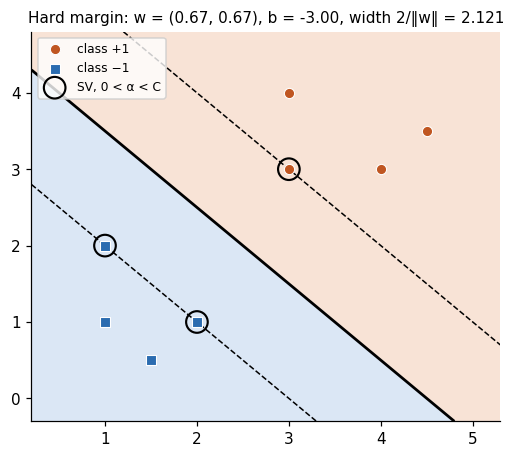

,x1,x2,y,α,f(x),y·f(x),"ξ = max(0, 1 − y·f)",category
0,1.0000,1.0000,-1,0.0000,-1.6667,1.6667,0.0000,α = 0 (not a SV)
1,2.0000,1.0000,-1,0.2222,-1.0000,1.0000,0.0000,0 < α < C (free SV)
2,1.0000,2.0000,-1,0.2222,-1.0000,1.0000,0.0000,0 < α < C (free SV)
3,1.5000,0.5000,-1,0.0000,-1.6667,1.6667,0.0000,α = 0 (not a SV)
4,3.0000,3.0000,1,0.4444,1.0000,1.0000,0.0000,0 < α < C (free SV)
5,4.0000,3.0000,1,0.0000,1.6667,1.6667,0.0000,α = 0 (not a SV)
6,3.0000,4.0000,1,0.0000,1.6667,1.6667,0.0000,α = 0 (not a SV)
7,4.5000,3.5000,1,0.0000,2.3333,2.3333,0.0000,α = 0 (not a SV)


Only **3 of 8** points are support vectors; they all have $y_i f(x_i) = 1$, every other point has $y_i f(x_i) > 1$. Removing any non-support vector would not move the hyperplane.

In [2]:
X_sep = np.array([[1, 1], [2, 1], [1, 2], [1.5, 0.5], [3, 3], [4, 3], [3, 4], [4.5, 3.5]], dtype=float)
y_sep = np.array([-1, -1, -1, -1, 1, 1, 1, 1])
hard = SMOSVC(C=1e6, kernel="linear", tol=1e-8).fit(X_sep, y_sep)

w, b = hard.coef_, hard.intercept_
width = 2 / np.linalg.norm(w)
fig, ax = plt.subplots(figsize=(5.5, 4.6))
plot_svm(ax, hard, X_sep, y_sep, f"Hard margin: w = ({w[0]:.2f}, {w[1]:.2f}), b = {b:.2f}, width 2/‖w‖ = {width:.3f}")
ax.legend(fontsize=8, loc="upper left"); plt.show()

display(alpha_table(hard, X_sep, y_sep))
margins = y_sep * hard.decision_function(X_sep)
assert np.all(margins >= 1 - 1e-6), "every point must satisfy y·f(x) ≥ 1"
assert np.allclose(margins[hard.support_], 1, atol=1e-6), "support vectors lie exactly on the margin"
display(Markdown(f"Only **{len(hard.support_)} of {len(X_sep)}** points are support vectors; they all have "
                 f"$y_i f(x_i) = 1$, every other point has $y_i f(x_i) > 1$. Removing any non-support vector "
                 f"would not move the hyperplane."))

## 2 · From the primal to the dual problem

Introduce one Lagrange multiplier $\alpha_i \ge 0$ per constraint:

$$\mathcal{L}(w, b, \alpha) = \frac12\lVert w\rVert^2 - \sum_i \alpha_i \big[\, y_i (w^\top x_i + b) - 1 \,\big].$$

Setting the derivatives with respect to the primal variables to zero:

$$\frac{\partial \mathcal{L}}{\partial w} = 0 \ \Rightarrow\ w = \sum_i \alpha_i y_i x_i,
\qquad \frac{\partial \mathcal{L}}{\partial b} = 0 \ \Rightarrow\ \sum_i \alpha_i y_i = 0.$$

Substituting back eliminates $w$ and $b$ and gives the **dual problem**
(written as a minimisation, the form our solver uses):

$$\min_{\alpha}\ \frac12 \sum_{i,j} \alpha_i \alpha_j y_i y_j\, x_i^\top x_j - \sum_i \alpha_i
\quad \text{s.t.}\quad \alpha_i \ge 0,\ \ \sum_i \alpha_i y_i = 0.$$

Two consequences drive everything that follows:

1. The data appear **only through inner products** $x_i^\top x_j$ (Section 5 replaces them by a kernel).
2. The **KKT complementary-slackness** condition $\alpha_i\,[\,y_i f(x_i) - 1\,] = 0$ forces $\alpha_i = 0$ for every
   point strictly outside the margin. Only points on the margin can have $\alpha_i > 0$: these are the
   **support vectors**, and $w$ is a combination of them alone.

The cell checks both facts on the model of Section 1.

In [3]:
w_from_alpha = (hard.alpha_ * y_sep) @ X_sep
slackness = hard.alpha_ * (y_sep * hard.decision_function(X_sep) - 1)
checks = pd.DataFrame({
    "quantity": ["w from the solver", "w = Σ αᵢ yᵢ xᵢ", "Σ αᵢ yᵢ", "max |αᵢ (yᵢ f(xᵢ) − 1)|"],
    "value": [np.round(hard.coef_, 4), np.round(w_from_alpha, 4), round(float(hard.alpha_ @ y_sep), 8),
              f"{np.abs(slackness).max():.1e}"],
})
display(checks)
assert np.allclose(w_from_alpha, hard.coef_) and abs(hard.alpha_ @ y_sep) < 1e-8 and np.abs(slackness).max() < 1e-5

,quantity,value
0,w from the solver,"[0.6667, 0.6667]"
1,w = Σ αᵢ yᵢ xᵢ,"[0.6667, 0.6667]"
2,Σ αᵢ yᵢ,-0.0000
3,max |αᵢ (yᵢ f(xᵢ) − 1)|,4.7e-10


## 3 · Worked example: one SMO step by hand

The dual has one variable per point but the constraint $\sum_i \alpha_i y_i = 0$ couples them, so a single
$\alpha_i$ cannot move alone. **SMO (Sequential Minimal Optimization)** updates **two** multipliers at a time,
which has a closed-form solution. With $u_t = \sum_j \alpha_j y_j K_{tj}$ and the error $E_t = u_t - y_t$:

| Step | Formula |
|---|---|
| Can grow / shrink | $I_{up} = \{y_t = +1, \alpha_t < C\} \cup \{y_t = -1, \alpha_t > 0\}$, $I_{low} = \{y_t = +1, \alpha_t > 0\} \cup \{y_t = -1, \alpha_t < C\}$ |
| Pick $i$ | $i = \arg\max_{t \in I_{up}} (-E_t)$, $m = -E_i$, $M = \min_{t \in I_{low}} (-E_t)$; stop if $m - M <$ tol |
| Pick $j$ | $j = \arg\max_{t \in I_{low},\, -E_t < m} \dfrac{(m + E_t)^2}{\eta_{it}}$ (second-order gain) |
| Curvature | $\eta = K_{ii} + K_{jj} - 2K_{ij}$ |
| Box $[L, H]$ | $y_i \ne y_j$: $L = \max(0, \alpha_j - \alpha_i)$, $H = \min(C, C + \alpha_j - \alpha_i)$; $y_i = y_j$: $L = \max(0, \alpha_i + \alpha_j - C)$, $H = \min(C, \alpha_i + \alpha_j)$ |
| Update $\alpha_j$ | $\alpha_j^{new} = \text{clip}\big(\alpha_j + y_j (E_i - E_j)/\eta,\ L,\ H\big)$ |
| Update $\alpha_i$ | $\alpha_i^{new} = \alpha_i + y_i y_j (\alpha_j - \alpha_j^{new})$ (keeps $\sum \alpha y = 0$) |
| Bias | $b = -\text{mean}(E_t)$ over free support vectors ($0 < \alpha_t < C$) |

**Data:** $x_1 = (1,1),\ y_1 = -1$; $x_2 = (2,2),\ y_2 = +1$; $x_3 = (3,3),\ y_3 = +1$; linear kernel, $C = 10$.
The next cell performs every step with plain NumPy, then compares each number with the trace recorded
by our solver (`record_trace=True`).

In [4]:
X3 = np.array([[1, 1], [2, 2], [3, 3]], dtype=float)
y3 = np.array([-1.0, 1.0, 1.0])
C3 = 10.0
K = X3 @ X3.T                                   # linear kernel K_ij = x_i · x_j
alpha = np.zeros(3)
E = (alpha * y3) @ K - y3                       # all α = 0 → u = 0 → E = −y
display(Markdown("**Kernel matrix and initial errors**"))
display(pd.DataFrame(K, index=["x1", "x2", "x3"], columns=["x1", "x2", "x3"]))
display(pd.DataFrame({"y": y3, "E = u − y": E, "−E": -E}, index=["x1", "x2", "x3"]))

up = ((y3 > 0) & (alpha < C3)) | ((y3 < 0) & (alpha > 0))
low = ((y3 > 0) & (alpha > 0)) | ((y3 < 0) & (alpha < C3))
score = -E
i = np.flatnonzero(up)[np.argmax(score[up])]
m, M = score[i], score[low].min()
eta_all = np.diag(K)[i] + np.diag(K) - 2 * K[i]
eta_all = np.where(eta_all > 0, eta_all, 1e-12)  # η ≤ 0 (t = i or duplicate points) → τ, as in the solver
gain = np.where(low & (score < m), (m - score) ** 2 / eta_all, -np.inf)
j = int(np.argmax(gain))
eta = eta_all[j]
L, H = (max(0, alpha[j] - alpha[i]), min(C3, C3 + alpha[j] - alpha[i])) if y3[i] != y3[j] else \
       (max(0, alpha[i] + alpha[j] - C3), min(C3, alpha[i] + alpha[j]))
aj_new = np.clip(alpha[j] + y3[j] * (E[i] - E[j]) / eta, L, H)
ai_new = alpha[i] + y3[i] * y3[j] * (alpha[j] - aj_new)
alpha[i], alpha[j] = ai_new, aj_new
E = (alpha * y3) @ K - y3
free = (alpha > 0) & (alpha < C3)
b_hand = -E[free].mean()
w_hand = (alpha * y3) @ X3

steps = pd.DataFrame([
    ("I_up / I_low", f"I_up = {list(np.flatnonzero(up) + 1)}, I_low = {list(np.flatnonzero(low) + 1)}"),
    ("pick i (largest −E in I_up)", f"i = x{i + 1}, m = {m:+.1f}, M = {M:+.1f}, gap m − M = {m - M:.1f} > tol"),
    ("second-order gain over I_low", ", ".join(f"x{t + 1}: {g:.2f}" for t, g in enumerate(gain) if np.isfinite(g))),
    ("pick j", f"j = x{j + 1}"),
    ("η = K_ii + K_jj − 2K_ij", f"{K[i, i]:.0f} + {K[j, j]:.0f} − 2·{K[i, j]:.0f} = {eta:.0f}"),
    ("box [L, H] (y_i ≠ y_j)" if y3[i] != y3[j] else "box [L, H] (y_i = y_j)", f"[{L:.0f}, {H:.0f}]"),
    ("α_j new = clip(α_j + y_j (E_i − E_j)/η)", f"0 + ({y3[j]:+.0f})·({-1 * y3[i]:+.0f} − ({-1 * y3[j]:+.0f}))/{eta:.0f} = {aj_new:.0f}"),
    ("α_i new = α_i + y_i y_j (α_j − α_j new)", f"{ai_new:.0f}"),
    ("updated errors E", ", ".join(f"x{t + 1}: {e:+.0f}" for t, e in enumerate(E))),
    ("bias b = −mean(E) over free SVs", f"{b_hand:+.0f}"),
    ("w = Σ αᵢ yᵢ xᵢ", f"({w_hand[0]:.0f}, {w_hand[1]:.0f})"),
], columns=["step", "computation"]).set_index("step")
display(steps)

**Kernel matrix and initial errors**

,x1,x2,x3
x1,2.0000,4.0000,6.0000
x2,4.0000,8.0000,12.0000
x3,6.0000,12.0000,18.0000


,y,E = u − y,−E
x1,-1.0000,1.0000,-1.0000
x2,1.0000,-1.0000,1.0000
x3,1.0000,-1.0000,1.0000


,computation
step,
I_up / I_low,"I_up = [2, 3], I_low = [1]"
pick i (largest −E in I_up),"i = x2, m = +1.0, M = -1.0, gap m − M = 2.0 > tol"
second-order gain over I_low,x1: 2.00
pick j,j = x1
η = K_ii + K_jj − 2K_ij,8 + 2 − 2·4 = 2
"box [L, H] (y_i ≠ y_j)","[0, 10]"
α_j new = clip(α_j + y_j (E_i − E_j)/η),0 + (-1)·(-1 − (+1))/2 = 1
α_i new = α_i + y_i y_j (α_j − α_j new),1
updated errors E,"x1: +3, x2: +3, x3: +5"


,by hand,SMO solver
i,1.0000,1.0000
j,0.0000,0.0000
η,2.0000,2.0000
L,0.0000,0.0000
H,10.0000,10.0000
α_i,1.0000,1.0000
α_j,1.0000,1.0000
b,-3.0000,-3.0000
w₁,1.0000,1.0000
w₂,1.0000,1.0000


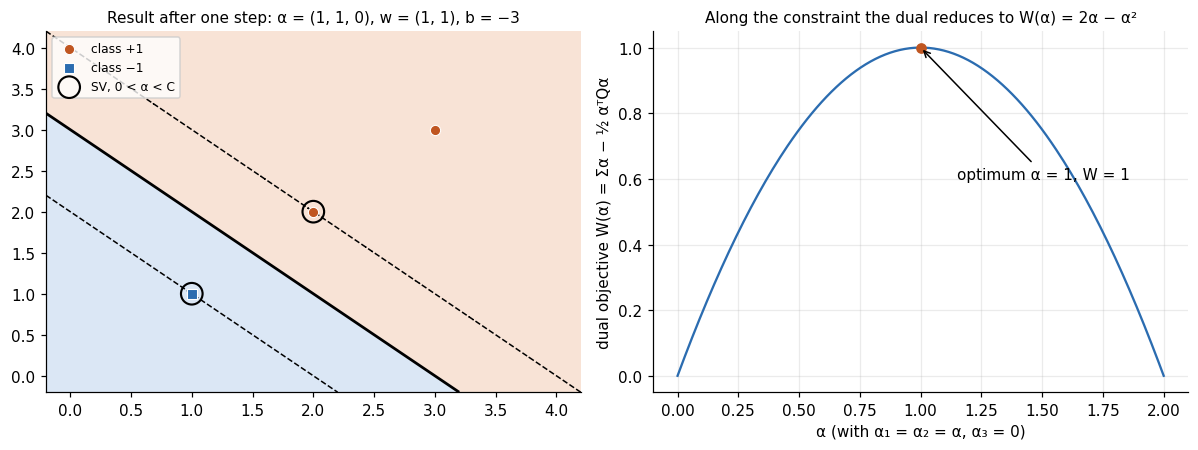

After the step the KKT gap is 0, so SMO stops after **1 iteration**. $x_3$ has $y_3 f(x_3) = 3 > 1$, so $\alpha_3 = 0$: it is not a support vector. The margin width $2/\lVert w\rVert = \sqrt{2} \approx 1.414$ equals the distance between $x_1$ and $x_2$.

In [5]:
smo = SMOSVC(C=C3, kernel="linear", tol=1e-6, record_trace=True).fit(X3, y3)
(trace,) = smo.trace_                                   # exactly one SMO iteration
comparison = pd.DataFrame({
    "by hand": [i, j, eta, L, H, ai_new, aj_new, b_hand, *w_hand],
    "SMO solver": [trace["i"], trace["j"], trace["eta"], trace["L"], trace["H"], trace["alpha_i"][1],
                   trace["alpha_j"][1], smo.intercept_, *smo.coef_],
}, index=["i", "j", "η", "L", "H", "α_i", "α_j", "b", "w₁", "w₂"])
display(comparison)
assert np.allclose(comparison["by hand"], comparison["SMO solver"]) and smo.n_iter_ == 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_svm(axes[0], smo, X3, y3, "Result after one step: α = (1, 1, 0), w = (1, 1), b = −3", pad=1.2)
axes[0].legend(fontsize=8, loc="upper left")
a = np.linspace(0, 2, 200)
axes[1].plot(a, 2 * a - a ** 2, color="#2b6cb0")
axes[1].scatter([1], [1], color="#c05621", zorder=3)
axes[1].annotate("optimum α = 1, W = 1", (1, 1), xytext=(1.15, 0.6), arrowprops={"arrowstyle": "->"})
axes[1].set_xlabel("α (with α₁ = α₂ = α, α₃ = 0)"); axes[1].set_ylabel("dual objective W(α) = Σα − ½ αᵀQα")
axes[1].set_title("Along the constraint the dual reduces to W(α) = 2α − α²", fontsize=10)
plt.tight_layout(); plt.show()
display(Markdown(f"After the step the KKT gap is 0, so SMO stops after **{smo.n_iter_} iteration**. "
                 f"$x_3$ has $y_3 f(x_3) = {y3[2] * smo.decision_function(X3)[2]:.0f} > 1$, so $\\alpha_3 = 0$: it is not a support vector. "
                 f"The margin width $2/\\lVert w\\rVert = \\sqrt{{2}} \\approx {2 / np.linalg.norm(smo.coef_):.3f}$ equals the distance between $x_1$ and $x_2$."))

## 4 · Soft margin: slack variables, C and the hinge loss

Real data overlap, so the hard-margin constraints have no solution. The **soft margin** gives each point a
**slack** $\xi_i \ge 0$ and charges $C$ per unit of violation:

$$\min_{w,\,b,\,\xi}\ \frac12\lVert w\rVert^2 + C \sum_i \xi_i \quad \text{s.t.} \quad y_i(w^\top x_i + b) \ge 1 - \xi_i,\ \ \xi_i \ge 0.$$

At the optimum $\xi_i = \max(0,\ 1 - y_i f(x_i))$, so the problem is **regularised hinge-loss minimisation**,
$\tfrac12\lVert w\rVert^2 + C\sum_i \max(0, 1 - y_i f(x_i))$. In the dual the only change is the
**box constraint** $0 \le \alpha_i \le C$, and the KKT conditions sort every point into one of three cases:

| $\alpha_i$ | Position | $\xi_i$ |
|---|---|---|
| $0$ | outside the margin, $y_i f(x_i) \ge 1$ | $0$ |
| $0 < \alpha_i < C$ (free SV) | exactly on the margin, $y_i f(x_i) = 1$ | $0$ |
| $C$ (bounded SV) | inside the margin ($0 < \xi_i \le 1$) or misclassified ($\xi_i > 1$) | $1 - y_i f(x_i)$ |

**Small example:** the 3 points of Section 3 plus $x_4 = (2.5, 2.5)$ labelled $-1$, which sits between two
positive points, so no line separates the data. $C = 1$.

In [6]:
X4 = np.vstack([X3, [2.5, 2.5]])
y4 = np.append(y3, -1.0)
soft4 = SMOSVC(C=1.0, kernel="linear", tol=1e-8).fit(X4, y4)
table4 = alpha_table(soft4, X4, y4)
display(table4)

margin4 = y4 * soft4.decision_function(X4)
a4 = soft4.alpha_
assert np.all(margin4[a4 <= 1e-8] >= 1 - 1e-6)                          # α = 0  → outside the margin
assert np.allclose(margin4[(a4 > 1e-8) & (a4 < 1 - 1e-8)], 1, atol=1e-6)  # 0<α<C → on the margin
assert np.all(margin4[a4 >= 1 - 1e-8] <= 1 + 1e-6)                       # α = C  → violates the margin
assert abs(a4 @ y4) < 1e-8 and np.all((a4 >= 0) & (a4 <= 1))
bounded = table4[table4["category"].str.startswith("α = C")]
display(Markdown(f"KKT holds for every point. Bounded support vectors (α = C): "
                 + ", ".join(f"x{k + 1} with ξ = {r['ξ = max(0, 1 − y·f)']:.3f}" for k, r in bounded.iterrows())
                 + ". A slack above 1 means the point is misclassified; $\\sum_i \\xi_i$ is an upper bound on the "
                 f"number of training errors ({(margin4 < 0).sum()} here)."))

,x1,x2,y,α,f(x),y·f(x),"ξ = max(0, 1 − y·f)",category
0,1.0000,1.0000,-1.0000,0.5000,-1.0000,1.0000,0.0000,0 < α < C (free SV)
1,2.0000,2.0000,1.0000,1.0000,0.0000,0.0000,1.0000,α = C (bounded SV)
2,3.0000,3.0000,1.0000,0.5000,1.0000,1.0000,0.0000,0 < α < C (free SV)
3,2.5000,2.5000,-1.0000,1.0000,0.5000,-0.5000,1.5000,α = C (bounded SV)


KKT holds for every point. Bounded support vectors (α = C): x2 with ξ = 1.000, x4 with ξ = 1.500. A slack above 1 means the point is misclassified; $\sum_i \xi_i$ is an upper bound on the number of training errors (1 here).

### The role of C on overlapping data

$C$ trades margin width against violations: a **small C** accepts many violations for a wide margin (high
bias, many support vectors); a **large C** narrows the margin to classify more training points correctly
(high variance). As $C \to \infty$ the soft margin tends to the hard margin.

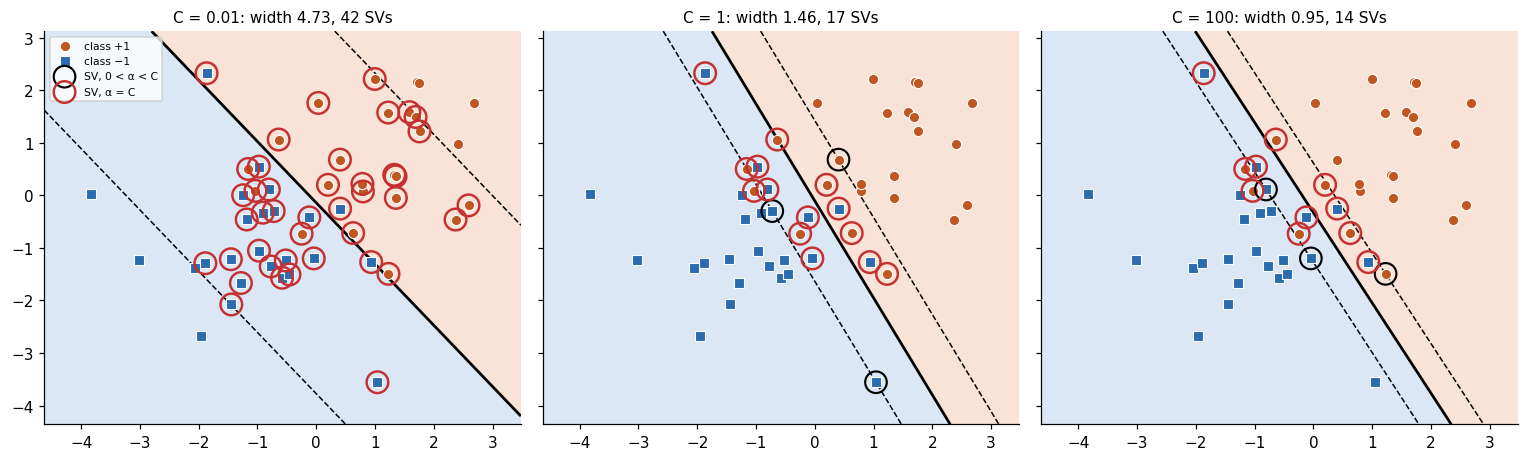

,margin width 2/‖w‖,support vectors,α = C,Σ ξ,training errors
C,,,,,
0.0100,4.7297,42,42,24.1192,5
1.0000,1.4571,17,14,12.8686,6
100.0000,0.9506,14,11,12.3644,5


In [7]:
rng = np.random.default_rng(3)
X_ov = np.vstack([rng.normal([-1, -1], 1.0, (25, 2)), rng.normal([1, 1], 1.0, (25, 2))])
y_ov = np.array([-1] * 25 + [1] * 25)
rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, C in zip(axes, [0.01, 1, 100]):
    model = SMOSVC(C=C, kernel="linear", tol=1e-6).fit(X_ov, y_ov)
    margin = y_ov * model.decision_function(X_ov)
    width = 2 / np.linalg.norm(model.coef_)
    plot_svm(ax, model, X_ov, y_ov, f"C = {C}: width {width:.2f}, {len(model.support_)} SVs")
    rows.append({"C": C, "margin width 2/‖w‖": width, "support vectors": len(model.support_),
                 "α = C": int((model.alpha_ >= C * (1 - 1e-8)).sum()), "Σ ξ": np.maximum(0, 1 - margin).sum(),
                 "training errors": int((margin < 0).sum())})
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("C"))

### Hinge loss versus other losses

All three losses below are functions of $y f(x)$. The **hinge loss is exactly zero once $y f(x) \ge 1$**, so
points outside the margin contribute nothing: this is why the SVM solution is **sparse** (only support vectors
matter). The logistic loss of Logistic Regression is never zero, so every point keeps a small influence.

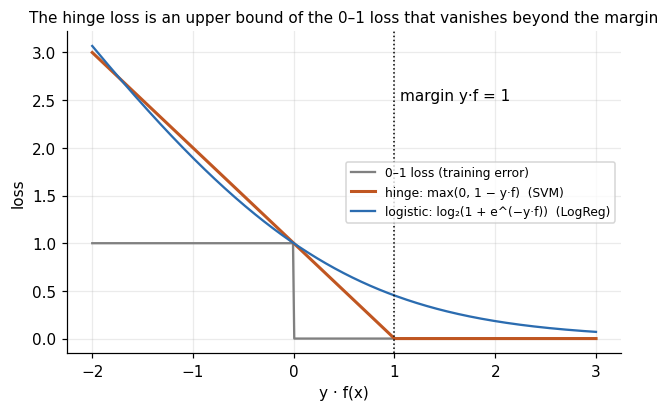

In [8]:
z = np.linspace(-2, 3, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(z, (z < 0).astype(float), color="gray", label="0–1 loss (training error)")
ax.plot(z, np.maximum(0, 1 - z), color="#c05621", lw=2, label="hinge: max(0, 1 − y·f)  (SVM)")
ax.plot(z, np.log2(1 + np.exp(-z)), color="#2b6cb0", label="logistic: log₂(1 + e^(−y·f))  (LogReg)")
ax.axvline(1, color="black", ls=":", lw=1); ax.text(1.05, 2.5, "margin y·f = 1")
ax.set_xlabel("y · f(x)"); ax.set_ylabel("loss"); ax.legend(fontsize=8)
ax.set_title("The hinge loss is an upper bound of the 0–1 loss that vanishes beyond the margin", fontsize=10)
plt.show()

## 5 · The kernel trick: XOR solved by hand

The dual (Section 2) needs only inner products, so we can replace $x_i^\top x_j$ by a **kernel**
$K(x_i, x_j) = \varphi(x_i)^\top \varphi(x_j)$: the SVM then finds a linear separator in the feature space of
$\varphi$ **without ever computing $\varphi$**. The decision function becomes

$$f(x) = \sum_{i \in SV} \alpha_i y_i K(x_i, x) + b.$$

**XOR** is the classic dataset no line can separate: $(1, 1)$ and $(-1, -1)$ are $+1$; $(1, -1)$ and $(-1, 1)$
are $-1$. Use the polynomial kernel $K(x, z) = (x^\top z)^2$. Expanding it shows the hidden feature map:

$$(x^\top z)^2 = (x_1 z_1 + x_2 z_2)^2 = x_1^2 z_1^2 + 2 x_1 x_2 z_1 z_2 + x_2^2 z_2^2 = \varphi(x)^\top \varphi(z),
\qquad \varphi(x) = (x_1^2,\ \sqrt{2}\, x_1 x_2,\ x_2^2).$$

In that 3-D space the second coordinate $\sqrt2\, x_1 x_2$ is $+\sqrt2$ for class $+1$ and $-\sqrt2$ for class
$-1$: the data become linearly separable.

**Solving the dual by hand.** $x_i^\top x_j \in \{2, 0, -2\}$, so $K_{ij} = 4$ within a class and $0$ across
classes. Note that $\varphi(1, 1) = \varphi(-1, -1) = (1, \sqrt2, 1)$: the two points of a class become **the same
point** in feature space, so only the class sums $s_+ = \alpha_1 + \alpha_2$ and $s_- = \alpha_3 + \alpha_4$ matter.
The constraint $\sum_i \alpha_i y_i = 0$ gives $s_+ = s_- = s$, and with $Q_{ij} = y_i y_j K_{ij}$ the dual objective is

$$\tfrac12 \sum_{i,j}\alpha_i\alpha_j Q_{ij} - \sum_i \alpha_i = \tfrac12\,(4 s_+^2 + 4 s_-^2) - 2s = 4s^2 - 2s,$$

minimised at $s = 1/4$ with value $-1/4$. Any split of $s$ inside a class is optimal (the solution in $\alpha$ is
not unique, the decision function is). The positive points both contribute $(x_1 + x_2)^2$, the negative ones
$(x_1 - x_2)^2$, and $b = 0$ by symmetry, so

$$f(x) = \tfrac14\big[(x_1 + x_2)^2 - (x_1 - x_2)^2\big] = x_1 x_2,$$

a hyperbola that separates XOR, with all four points exactly on the margin ($f = \pm 1$).

**Kernel matrix $K = (x^\top z)^2$ equals $\varphi(x)^\top\varphi(z)$ entry by entry:**

,"(1, 1)","(-1, -1)","(1, -1)","(-1, 1)"
"(1, 1)",4.0000,4.0000,0.0000,0.0000
"(-1, -1)",4.0000,4.0000,0.0000,0.0000
"(1, -1)",0.0000,0.0000,4.0000,4.0000
"(-1, 1)",0.0000,0.0000,4.0000,4.0000


,α,s₊ = α₁ + α₂,dual objective,b,training accuracy
model,,,,,
linear kernel,"[100.0, 100.0, 100.0, 100.0]",200.0000,-400.0000,-0.0000,0.5000
polynomial kernel (xᵀz)²,"[0.25, 0.0, 0.25, 0.0]",0.2500,-0.2500,-0.0000,1.0000


The solver returns one of the optimal splits; the hand result only fixes $s_+ = s_- = 1/4$, the dual value $-1/4$, $b = 0$ and $f(x) = x_1 x_2$, and all four are confirmed above.

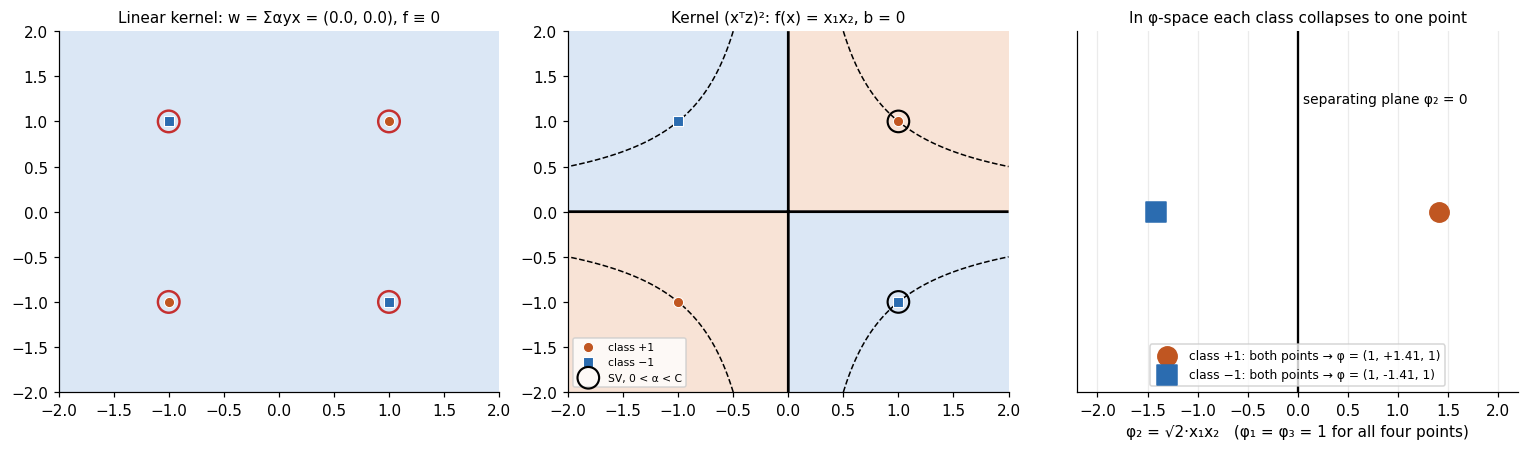

In [9]:
X_xor = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1]], dtype=float)
y_xor = np.array([1, 1, -1, -1])
phi = np.c_[X_xor[:, 0] ** 2, np.sqrt(2) * X_xor[:, 0] * X_xor[:, 1], X_xor[:, 1] ** 2]
K_poly = kernel_matrix(X_xor, X_xor, "poly", gamma=1.0, degree=2, coef0=0.0)
assert np.allclose(K_poly, phi @ phi.T), "kernel = inner product in φ-space"
display(Markdown("**Kernel matrix $K = (x^\\top z)^2$ equals $\\varphi(x)^\\top\\varphi(z)$ entry by entry:**"))
display(pd.DataFrame(K_poly, index=[str(tuple(p.astype(int))) for p in X_xor], columns=[str(tuple(p.astype(int))) for p in X_xor]))

poly = SMOSVC(C=100, kernel="poly", gamma=1.0, degree=2, coef0=0.0, tol=1e-8).fit(X_xor, y_xor)
linear = SMOSVC(C=100, kernel="linear", tol=1e-8).fit(X_xor, y_xor)
grid = np.random.default_rng(0).uniform(-2, 2, (500, 2))
assert np.isclose(poly.alpha_[:2].sum(), 1 / 4) and np.isclose(poly.alpha_[2:].sum(), 1 / 4), "class sums s = 1/4"
assert np.isclose(poly.dual_objective_, -1 / 4) and abs(poly.intercept_) < 1e-9, "dual value −1/4, b = 0"
assert np.allclose(poly.decision_function(grid), grid[:, 0] * grid[:, 1]), "f(x) = x1·x2 as derived by hand"
display(pd.DataFrame({
    "model": ["linear kernel", "polynomial kernel (xᵀz)²"],
    "α": [np.round(linear.alpha_, 3), np.round(poly.alpha_, 3)],
    "s₊ = α₁ + α₂": [round(linear.alpha_[:2].sum(), 3), round(poly.alpha_[:2].sum(), 3)],
    "dual objective": [round(linear.dual_objective_, 3), round(poly.dual_objective_, 3)],
    "b": [round(linear.intercept_, 3), round(poly.intercept_, 3)],
    "training accuracy": [(linear.predict(X_xor) == y_xor).mean(), (poly.predict(X_xor) == y_xor).mean()],
}).set_index("model"))
display(Markdown("The solver returns one of the optimal splits; the hand result only fixes $s_+ = s_- = 1/4$, "
                 "the dual value $-1/4$, $b = 0$ and $f(x) = x_1 x_2$, and all four are confirmed above."))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
plot_svm(axes[0], linear, X_xor, y_xor, f"Linear kernel: w = Σαyx = {tuple(np.round(linear.coef_, 6) + 0)}, f ≡ 0", pad=1)
plot_svm(axes[1], poly, X_xor, y_xor, "Kernel (xᵀz)²: f(x) = x₁x₂, b = 0", pad=1)
axes[1].legend(fontsize=7, loc="lower left")
for label, (color, marker, name) in CLASS.items():
    value = phi[y_xor == label, 1][0]
    axes[2].scatter([value], [0], c=color, marker=marker, s=160, label=f"{name}: both points → φ = (1, {value:+.2f}, 1)")
axes[2].axvline(0, color="black", lw=1.5); axes[2].text(0.05, 0.6, "separating plane φ₂ = 0", fontsize=9)
axes[2].set_xlim(-2.2, 2.2); axes[2].set_ylim(-1, 1); axes[2].set_yticks([])
axes[2].set_xlabel("φ₂ = √2·x₁x₂   (φ₁ = φ₃ = 1 for all four points)")
axes[2].set_title("In φ-space each class collapses to one point", fontsize=10); axes[2].legend(fontsize=8, loc="lower center")
plt.tight_layout(); plt.show()

## 6 · RBF kernel: the effect of γ and C

The RBF kernel $K(x, z) = \exp(-\gamma \lVert x - z \rVert^2)$ is a **similarity** between 0 and 1: 1 for
identical points, close to 0 for distant ones. Its feature map $\varphi$ is infinite-dimensional (the Taylor
series of $\exp$), which only the kernel trick makes usable.

- **γ** sets the radius of influence of each support vector: a small γ gives a smooth, almost linear boundary;
  a large γ lets each support vector affect only its immediate neighbourhood, so the boundary wraps around
  individual points.
- **C** plays the same role as in Section 4.

Small γ with small C **underfits**: the boundary is almost a straight line, training accuracy is low, and the
wide margin turns most points into support vectors. Large γ with large C **overfits**: the boundary wraps
around individual points, training accuracy approaches 100% while test accuracy falls. With only 50 test
points the test accuracy moves in steps of 2%, so small differences between panels are noise. This is the
bias–variance trade-off that the grid search of Part 2 explores on the phishing data.

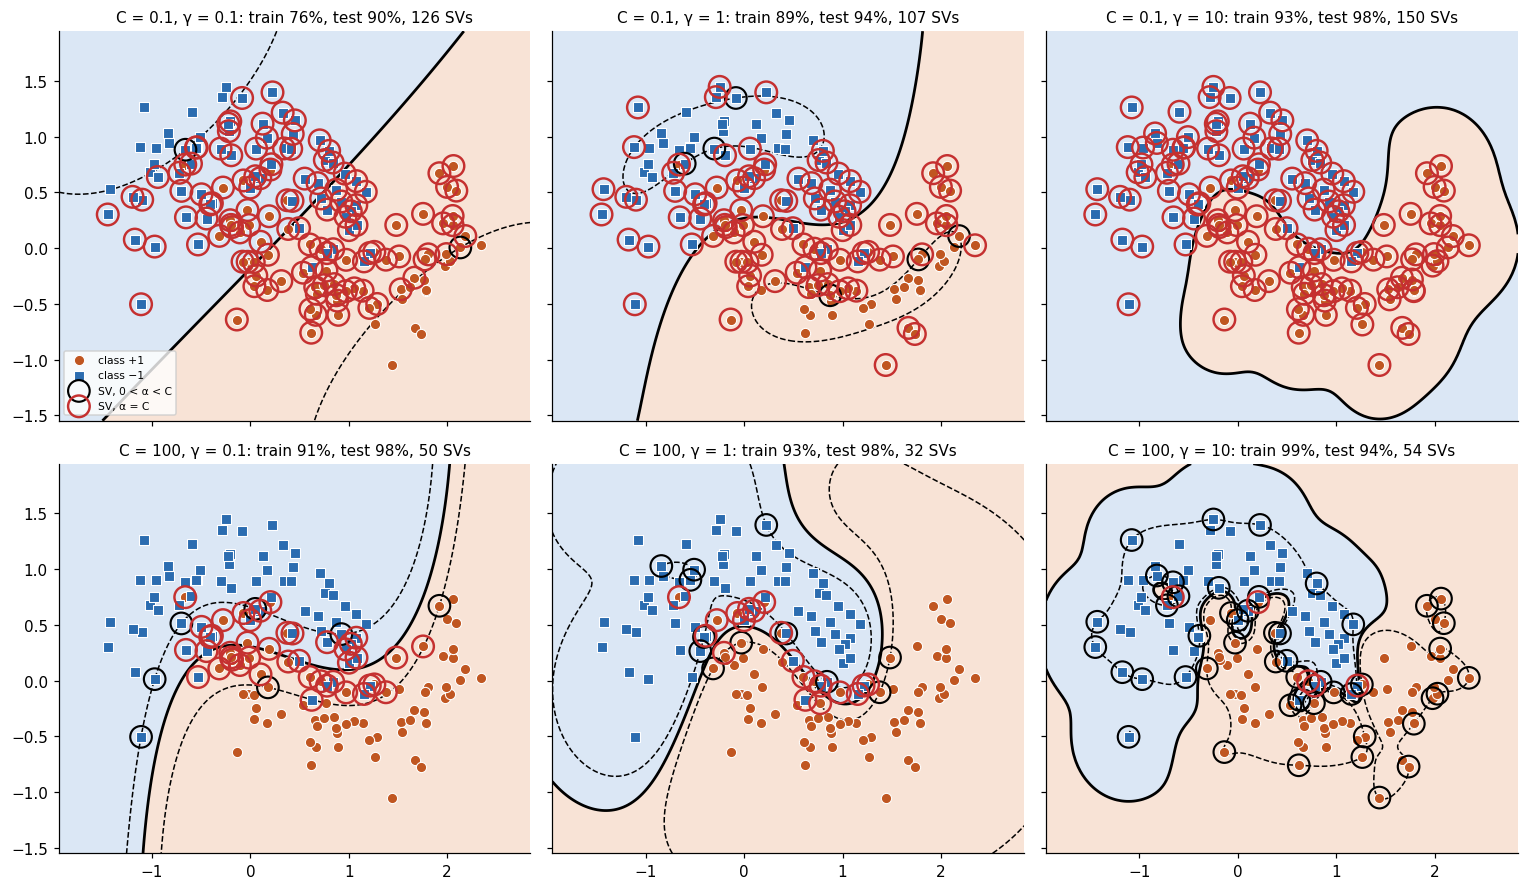

train accuracy  test accuracy  support vectors
C        γ                                                      
0.1000   0.1000           0.7600         0.9000              126
         1.0000           0.8933         0.9400              107
         10.0000          0.9333         0.9800              150
100.0000 0.1000           0.9133         0.9800               50
         1.0000           0.9333         0.9800               32
         10.0000          0.9867         0.9400               54

In [10]:
X_m, y_m = make_moons(n_samples=200, noise=0.25, random_state=0)
y_m = np.where(y_m == 1, 1, -1)
X_tr, y_tr, X_te, y_te = X_m[:150], y_m[:150], X_m[150:], y_m[150:]
rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8.2), sharex=True, sharey=True)
for r, C in enumerate([0.1, 100]):
    for c, gamma in enumerate([0.1, 1, 10]):
        model = SMOSVC(C=C, kernel="rbf", gamma=gamma).fit(X_tr, y_tr)
        train_acc, test_acc = (model.predict(X_tr) == y_tr).mean(), (model.predict(X_te) == y_te).mean()
        plot_svm(axes[r, c], model, X_tr, y_tr,
                 f"C = {C}, γ = {gamma}: train {train_acc:.0%}, test {test_acc:.0%}, {len(model.support_)} SVs", pad=0.5, steps=200)
        rows.append({"C": C, "γ": gamma, "train accuracy": train_acc, "test accuracy": test_acc,
                     "support vectors": len(model.support_)})
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index(["C", "γ"]))

## 7 · Link to the phishing model

The model used in Parts 2 and the demo is exactly this machinery in 17 dimensions: an RBF SVM with
$C = 1$, $\gamma = 0.3$, trained by the same SMO on 8,000 standardised hostnames (3,567 support vectors).

One property of the RBF kernel explains a limitation found in Part 2: **far from every support vector,
$K(x_i, x) \to 0$ for all $i$, so $f(x) \to b$**. The prediction is then decided by the bias, not by any
training example. The cell shows it on the moons model: as a point moves away from the data, $f(x)$
converges to $b$. On the phishing data 12.8% of test hostnames fall in this region.

In [11]:
model = SMOSVC(C=1, kernel="rbf", gamma=1).fit(X_tr, y_tr)
distances = [0, 1, 2, 3, 5, 8]
far = np.array([[2.0 + d, 2.0 + d] for d in distances])
sim = kernel_matrix(far, model.support_vectors_, "rbf", model.gamma_)
display(pd.DataFrame({
    "point": [str(tuple(p)) for p in far],
    "max K to any support vector": sim.max(1),
    "Σ |αᵢ yᵢ K(xᵢ, x)|": np.abs(sim * model.dual_coef_).sum(1),
    "f(x)": model.decision_function(far),
    "bias b": model.intercept_,
}).set_index("point"))
assert abs(model.decision_function(far[-1:])[0] - model.intercept_) < 1e-6

,max K to any support vector,"Σ |αᵢ yᵢ K(xᵢ, x)|",f(x),bias b
point,,,,
"(2.0, 2.0)",0.1703,0.4398,0.1046,-0.0250
"(3.0, 3.0)",0.0014,0.0016,-0.0236,-0.0250
"(4.0, 4.0)",0.0000,0.0000,-0.0250,-0.0250
"(5.0, 5.0)",0.0000,0.0000,-0.0250,-0.0250
"(7.0, 7.0)",0.0000,0.0000,-0.0250,-0.0250
"(10.0, 10.0)",0.0000,0.0000,-0.0250,-0.0250


## 8 · Where each concept lives in the code

| Concept | Section | Code (`src/smo.py`) |
|---|---|---|
| Kernels: linear, polynomial, RBF | 5, 6 | `kernel_matrix` |
| Dual problem, $E_t = u_t - y_t$ | 2, 3 | `SMOSVC.fit`: `E = -y_pm.copy()` at start, updated after each step |
| Working-set selection $I_{up}$, $I_{low}$, $m - M$ stopping rule | 3 | `SMOSVC.fit`: `up`, `low`, `if m - M < self.tol` |
| Second-order choice of $j$ | 3 | `SMOSVC.fit`: `gain = ... (m - score) ** 2 / eta_all` |
| Analytic update with $\eta$, $[L, H]$ clipping | 3, 4 | `SMOSVC.fit`: `eta`, `L, H`, `aj_new`, `ai_new` |
| Bias from free support vectors | 3 | `SMOSVC._bias` |
| $w = \sum_i \alpha_i y_i x_i$ (linear kernel) | 2 | `SMOSVC.coef_` |
| Decision function $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$ | 5, 7 | `SMOSVC.decision_function` |
| Step-by-step trace for hand calculations | 3 | `SMOSVC(record_trace=True).trace_` |

The automatic checks of these properties (3-point example, KKT conditions, equality with LIBSVM) are in
`tests/test_smo.py`.